# Задача 6. Затухание света в детекторе

**Цель:** ввести экспоненциальное ослабление света с длиной затухания \(\lambda=8\,\text{м}\), получить энергетический отклик для источника с энергией \(E_0=1\,\text{МэВ}\) в нескольких точках вертикальной оси детектора и сравнить его с моделью без затухания.

В ноутбуке используются две конфигурации:

1. **Без затухания:** весь зарегистрированный световой сигнал соответствует исходной энергии.
2. **С затуханием:** число зарегистрированных фотоэлектронов уменьшается в соответствии с законом Бугера–Ламберта–Бера.

Результаты моделирования воспроизводимы: генератор случайных чисел и его seed задаются явно.

## 1. Физическая модель и допущения

Для оптического пути длиной \(d\) коэффициент пропускания света равен

\[
T(d)=\exp\left(-\frac{d}{\lambda}\right),\qquad \lambda=8\,\text{м}.
\]

Считаем, что источник полностью передаёт детектору энергию \(E_0=1\,\text{МэВ}\), а фотоприёмник расположен в точке \(z_{\rm sens}\) на вертикальной оси. Тогда расстояние, которое проходит свет,

\[
d=|z_{\rm src}-z_{\rm sens}|.
\]

Для моделирования статистического энергетического отклика используем пуассоновскую статистику числа зарегистрированных фотоэлектронов:

\[
N_{\rm pe}\sim\operatorname{Poisson}\left(Y_{\rm pe} E_0 T(d)\right),
\qquad E_{\rm rec}=\frac{N_{\rm pe}}{Y_{\rm pe}}.
\]

Здесь \(Y_{\rm pe}\) — эффективный световыход в фотоэлектронах на МэВ, определённый для нулевого оптического пути. Поэтому

\[
\mathbb{E}[E_{\rm rec}]=E_0T(d),\qquad
\sigma_{E_{\rm rec}}=\frac{\sqrt{Y_{\rm pe}E_0T(d)}}{Y_{\rm pe}}.
\]

**Ограничения модели:** не моделируются перенос гамма-квантов, неполное энерговыделение, пространственная неоднородность световыхода, отражения на границах и собственное электронное уширение. В расчёте изолируется именно влияние экспоненциального оптического затухания и фотостатистики. Значения высоты детектора, координаты фотоприёмника и световыхода ниже являются настраиваемыми параметрами: в условии задачи они не указаны.

## 2. Импорт библиотек и параметры моделирования

При переносе ноутбука в основной репозиторий следует заменить демонстрационные параметры геометрии и световыхода на значения из предыдущих частей проекта.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Параметры, заданные условием задачи
SOURCE_ENERGY_MEV = 1.0
ATTENUATION_LENGTH_M = 8.0

# Геометрия и свойства фотодетектора — демонстрационные значения.
# Замените их параметрами вашего детектора из предыдущих заданий.
DETECTOR_HEIGHT_M = 1.0
SENSOR_Z_M = 0.0                 # фотоприёмник на нижнем торце
PE_YIELD_PER_MEV = 10_000.0      # эффективный световыход при d = 0, pe/MeV

# Численные параметры
N_EVENTS = 50_000
N_SOURCE_POSITIONS = 7
RANDOM_SEED = 20261102

assert SOURCE_ENERGY_MEV > 0
assert ATTENUATION_LENGTH_M > 0
assert DETECTOR_HEIGHT_M > 0
assert 0 <= SENSOR_Z_M <= DETECTOR_HEIGHT_M
assert PE_YIELD_PER_MEV > 0
assert N_EVENTS > 0

source_positions_m = np.linspace(0.0, DETECTOR_HEIGHT_M, N_SOURCE_POSITIONS)

print(f"Энергия источника: {SOURCE_ENERGY_MEV:.3f} МэВ")
print(f"Длина затухания:   {ATTENUATION_LENGTH_M:.3f} м")
print(f"Высота детектора:  {DETECTOR_HEIGHT_M:.3f} м (демонстрационное значение)")
print(f"Координата датчика: {SENSOR_Z_M:.3f} м")
print(f"Положения источника: {source_positions_m}")

Энергия источника: 1.000 МэВ
Длина затухания:   8.000 м
Высота детектора:  1.000 м (демонстрационное значение)
Координата датчика: 0.000 м
Положения источника: [0.         0.16666667 0.33333333 0.5        0.66666667 0.83333333
 1.        ]


## 3. Функции модели

Функция `attenuation_factor` вычисляет коэффициент пропускания. Функция `expected_visible_energy` возвращает аналитическое среднее реконструируемой энергии. `simulate_response` генерирует распределение энергии с учётом пуассоновской статистики фотоэлектронов.

In [2]:
def attenuation_factor(distance_m, attenuation_length_m=ATTENUATION_LENGTH_M):
    """Экспоненциальный коэффициент пропускания света exp(-d / lambda)."""
    distance = np.asarray(distance_m, dtype=float)
    if np.any(~np.isfinite(distance)) or np.any(distance < 0):
        raise ValueError("Расстояние должно быть конечным и неотрицательным")
    if not np.isfinite(attenuation_length_m) or attenuation_length_m <= 0:
        raise ValueError("Длина затухания должна быть конечной и положительной")
    result = np.exp(-distance / attenuation_length_m)
    return float(result) if result.ndim == 0 else result


def expected_visible_energy(
    energy_mev,
    distance_m,
    include_attenuation=True,
    attenuation_length_m=ATTENUATION_LENGTH_M,
):
    """Аналитическое среднее видимой энергии в МэВ."""
    if not np.isfinite(energy_mev) or energy_mev < 0:
        raise ValueError("Энергия должна быть конечной и неотрицательной")
    transmission = (
        attenuation_factor(distance_m, attenuation_length_m)
        if include_attenuation else 1.0
    )
    return energy_mev * transmission


def simulate_response(
    energy_mev,
    distance_m,
    n_events=N_EVENTS,
    pe_yield_per_mev=PE_YIELD_PER_MEV,
    include_attenuation=True,
    attenuation_length_m=ATTENUATION_LENGTH_M,
    rng=None,
):
    """Смоделировать массив реконструируемых энергий в МэВ.

    Калибровка E_rec = N_pe / Y_pe соответствует нулевому оптическому пути.
    При include_attenuation=False затухание света отключено.
    """
    if not np.isfinite(energy_mev) or energy_mev < 0:
        raise ValueError("Энергия должна быть конечной и неотрицательной")
    if not isinstance(n_events, (int, np.integer)) or n_events <= 0:
        raise ValueError("Число событий должно быть положительным целым")
    if not np.isfinite(pe_yield_per_mev) or pe_yield_per_mev <= 0:
        raise ValueError("Световыход должен быть конечным и положительным")

    if rng is None:
        rng = np.random.default_rng()

    transmission = (
        attenuation_factor(distance_m, attenuation_length_m)
        if include_attenuation else 1.0
    )
    mean_photoelectrons = pe_yield_per_mev * energy_mev * transmission
    photoelectrons = rng.poisson(mean_photoelectrons, size=n_events)
    return photoelectrons / pe_yield_per_mev

print("Функции модели определены.")

Функции модели определены.


## 4. Проверка закона затухания

Сначала проверим характерные значения коэффициента пропускания. На расстоянии, равном длине затухания, интенсивность уменьшается в \(e\) раз.

In [3]:
distances_m = np.array([0.0, 1.0, 4.0, 8.0, 16.0])
transmissions = attenuation_factor(distances_m)

attenuation_check = pd.DataFrame({
    "Расстояние d, м": distances_m,
    "Коэффициент exp(-d/lambda)": transmissions,
    "Ослабление, %": 100.0 * (1.0 - transmissions),
})
display(attenuation_check)

assert np.isclose(attenuation_factor(0.0), 1.0)
assert np.isclose(attenuation_factor(8.0), np.exp(-1.0))
assert np.all(np.diff(transmissions) < 0)
print(f"На расстоянии 8 м остаётся {100 * attenuation_factor(8.0):.2f}% исходного света.")

,"Расстояние d, м",Коэффициент exp(-d/lambda),"Ослабление, %"
0,0.0,1.000000,0.000000
1,1.0,0.882497,11.750310
2,4.0,0.606531,39.346934
3,8.0,0.367879,63.212056
4,16.0,0.135335,86.466472


На расстоянии 8 м остаётся 36.79% исходного света.


## 5. Моделирование энергетического отклика в разных точках

Для каждого положения источника генерируются две выборки с одинаковым числом событий: без затухания и с затуханием. Использование отдельных генераторов с фиксированными seed обеспечивает воспроизводимость результата.

In [4]:
responses = {}
summary_rows = []

for index, z_source_m in enumerate(source_positions_m):
    distance_m = abs(z_source_m - SENSOR_Z_M)

    # Один и тот же seed для двух сценариев в данной точке.
    # Это не меняет закон распределения, но делает сравнение стабильным.
    rng_no_attenuation = np.random.default_rng(RANDOM_SEED + index)
    rng_attenuation = np.random.default_rng(RANDOM_SEED + index)

    response_no = simulate_response(
        energy_mev=SOURCE_ENERGY_MEV,
        distance_m=distance_m,
        n_events=N_EVENTS,
        include_attenuation=False,
        rng=rng_no_attenuation,
    )
    response_with = simulate_response(
        energy_mev=SOURCE_ENERGY_MEV,
        distance_m=distance_m,
        n_events=N_EVENTS,
        include_attenuation=True,
        rng=rng_attenuation,
    )

    responses[(index, "no_attenuation")] = response_no
    responses[(index, "attenuation")] = response_with

    transmission = attenuation_factor(distance_m)
    expected_no = expected_visible_energy(SOURCE_ENERGY_MEV, distance_m, False)
    expected_with = expected_visible_energy(SOURCE_ENERGY_MEV, distance_m, True)

    summary_rows.append({
        "z источника, м": z_source_m,
        "Путь света, м": distance_m,
        "T(d)": transmission,
        "Среднее без затухания, МэВ": response_no.mean(),
        "Ожидание без затухания, МэВ": expected_no,
        "Среднее с затуханием, МэВ": response_with.mean(),
        "Ожидание с затуханием, МэВ": expected_with,
        "Сигма с затуханием, МэВ": response_with.std(ddof=1),
        "Падение среднего, %": 100.0 * (1.0 - transmission),
    })

results = pd.DataFrame(summary_rows)
display(results.round(5))

,"z источника, м","Путь света, м",T(d),"Среднее без затухания, МэВ","Ожидание без затухания, МэВ","Среднее с затуханием, МэВ","Ожидание с затуханием, МэВ","Сигма с затуханием, МэВ","Падение среднего, %"
0,0.00000,0.00000,1.00000,1.00001,1.0,1.00001,1.00000,0.00995,0.00000
1,0.16667,0.16667,0.97938,0.99990,1.0,0.97929,0.97938,0.00992,2.06178
2,0.33333,0.33333,0.95919,1.00002,1.0,0.95921,0.95919,0.00978,4.08105
3,0.50000,0.50000,0.93941,0.99988,1.0,0.93929,0.93941,0.00973,6.05869
4,0.66667,0.66667,0.92004,1.00007,1.0,0.92011,0.92004,0.00960,7.99556
5,0.83333,0.83333,0.90108,1.00006,1.0,0.90113,0.90108,0.00951,9.89249
6,1.00000,1.00000,0.88250,1.00000,1.0,0.88250,0.88250,0.00943,11.75031


## 6. Сравнение средних значений

На графике показаны аналитические ожидания и средние значения, полученные методом Монте-Карло. В отсутствие затухания среднее значение не зависит от координаты источника. При включении затухания оно определяется оптическим расстоянием до фотоприёмника.

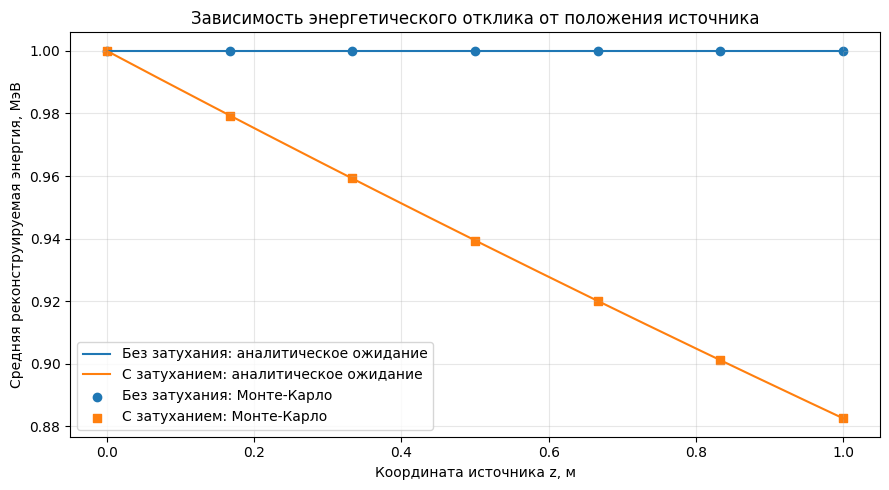

In [5]:
z_plot = np.linspace(0.0, DETECTOR_HEIGHT_M, 300)
d_plot = np.abs(z_plot - SENSOR_Z_M)
expected_with_curve = SOURCE_ENERGY_MEV * attenuation_factor(d_plot)
expected_no_curve = np.full_like(z_plot, SOURCE_ENERGY_MEV)

plt.figure(figsize=(9, 5))
plt.plot(z_plot, expected_no_curve, label="Без затухания: аналитическое ожидание")
plt.plot(z_plot, expected_with_curve, label="С затуханием: аналитическое ожидание")
plt.scatter(results["z источника, м"], results["Среднее без затухания, МэВ"],
            marker="o", label="Без затухания: Монте-Карло")
plt.scatter(results["z источника, м"], results["Среднее с затуханием, МэВ"],
            marker="s", label="С затуханием: Монте-Карло")
plt.xlabel("Координата источника z, м")
plt.ylabel("Средняя реконструируемая энергия, МэВ")
plt.title("Зависимость энергетического отклика от положения источника")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Сравнение распределений энергии

Для наглядности сравним распределения в двух положениях: рядом с фотоприёмником и в наиболее удалённой точке оси. При нулевом оптическом пути оба сценария должны совпадать; на максимальном расстоянии включение затухания смещает распределение к меньшим энергиям.

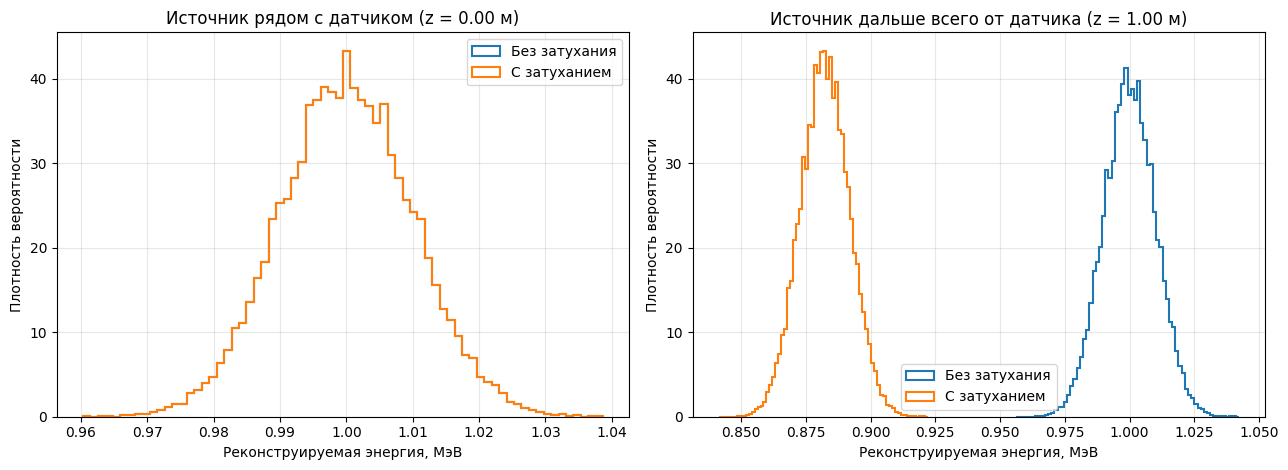

In [6]:
near_index = int(np.argmin(np.abs(source_positions_m - SENSOR_Z_M)))
far_index = int(np.argmax(np.abs(source_positions_m - SENSOR_Z_M)))

near_no = responses[(near_index, "no_attenuation")]
near_with = responses[(near_index, "attenuation")]
far_no = responses[(far_index, "no_attenuation")]
far_with = responses[(far_index, "attenuation")]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].hist(near_no, bins=70, density=True, histtype="step", linewidth=1.5,
             label="Без затухания")
axes[0].hist(near_with, bins=70, density=True, histtype="step", linewidth=1.5,
             label="С затуханием")
axes[0].set_title(f"Источник рядом с датчиком (z = {source_positions_m[near_index]:.2f} м)")
axes[0].set_xlabel("Реконструируемая энергия, МэВ")
axes[0].set_ylabel("Плотность вероятности")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].hist(far_no, bins=70, density=True, histtype="step", linewidth=1.5,
             label="Без затухания")
axes[1].hist(far_with, bins=70, density=True, histtype="step", linewidth=1.5,
             label="С затуханием")
axes[1].set_title(f"Источник дальше всего от датчика (z = {source_positions_m[far_index]:.2f} м)")
axes[1].set_xlabel("Реконструируемая энергия, МэВ")
axes[1].set_ylabel("Плотность вероятности")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Автоматические тесты модели (`pytest`)

В лекции тесты рассматриваются как проверяемый контракт поведения программы. Ниже используются параметризация `pytest.mark.parametrize` и fixture для фиксированного seed. Проверяются аналитический закон затухания, отсутствие зависимости от координаты при отключённом затухании, статистическое среднее и воспроизводимость генерации.

In [7]:
# Передадим функции модели во временный модуль, чтобы pytest мог импортировать их
# из отдельного тестового файла, как в обычной структуре проекта.
import sys
import types
import tempfile
from pathlib import Path
import textwrap
import pytest

_model_module_name = "attenuation_model_for_pytest"
_model_module = types.ModuleType(_model_module_name)
_model_module.attenuation_factor = attenuation_factor
_model_module.expected_visible_energy = expected_visible_energy
_model_module.simulate_response = simulate_response
sys.modules[_model_module_name] = _model_module

test_source = r"""import numpy as np
import pytest
from attenuation_model_for_pytest import (
    attenuation_factor,
    expected_visible_energy,
    simulate_response,
)

@pytest.mark.parametrize(
    "distance, expected",
    [(0.0, 1.0), (8.0, np.exp(-1.0)), (16.0, np.exp(-2.0))],
)
def test_attenuation_factor(distance, expected):
    assert np.isclose(attenuation_factor(distance, 8.0), expected)

@pytest.mark.parametrize("distance", [0.0, 0.5, 2.0, 8.0, 16.0])
def test_disabling_attenuation_keeps_energy(distance):
    assert np.isclose(
        expected_visible_energy(1.0, distance, include_attenuation=False), 1.0
    )

@pytest.fixture
def fixed_rng_seed():
    return 314159

def test_reproducible_simulation(fixed_rng_seed):
    first = simulate_response(
        1.0, 3.0, n_events=5000, include_attenuation=True,
        rng=np.random.default_rng(fixed_rng_seed),
    )
    second = simulate_response(
        1.0, 3.0, n_events=5000, include_attenuation=True,
        rng=np.random.default_rng(fixed_rng_seed),
    )
    assert np.array_equal(first, second)

def test_simulated_mean_matches_expectation():
    sample = simulate_response(
        1.0, 8.0, n_events=50000, pe_yield_per_mev=10000.0,
        include_attenuation=True, rng=np.random.default_rng(1234),
    )
    expected = expected_visible_energy(1.0, 8.0, include_attenuation=True)
    assert abs(sample.mean() - expected) < 5e-4
"""

with tempfile.TemporaryDirectory() as tmp_dir:
    test_file = Path(tmp_dir) / "test_attenuation_model.py"
    test_file.write_text(textwrap.dedent(test_source), encoding="utf-8")
    pytest_result = pytest.main(["-q", str(test_file)])

assert pytest_result == pytest.ExitCode.OK, "Не все тесты модели пройдены"
print("Все автоматические тесты пройдены.")

.

.

.

.

.

.

... (3 outputs left out)

.

                                                               [100%]


10 passed in 0.22s


Все автоматические тесты пройдены.


## 9. Итог и физическая интерпретация

- Без затухания среднее реконструируемой энергии не зависит от координаты источника и равно \(1\,\text{МэВ}\).
- При включении затухания среднее значение уменьшается как \(E_0\exp(-d/8\,\text{м})\).
- Ширина распределения в данной модели обусловлена фотостатистикой; при уменьшении числа фотоэлектронов относительные флуктуации возрастают.
- Величина эффекта определяется отношением оптического пути к длине затухания. Поэтому для окончательного результата необходимо подставить фактическую высоту детектора и координату фотоприёмника.

**Проверка для демонстрационной геометрии:**

In [8]:
max_distance_m = float(np.max(np.abs(source_positions_m - SENSOR_Z_M)))
max_transmission = attenuation_factor(max_distance_m)
max_expected_energy = SOURCE_ENERGY_MEV * max_transmission

print(f"Максимальный оптический путь: {max_distance_m:.3f} м")
print(f"Передача света на этом пути: {max_transmission:.5f}")
print(f"Ожидаемая энергия в дальней точке: {max_expected_energy:.5f} МэВ")
print(f"Снижение среднего отклика: {100 * (1 - max_transmission):.2f}%")

Максимальный оптический путь: 1.000 м
Передача света на этом пути: 0.88250
Ожидаемая энергия в дальней точке: 0.88250 МэВ
Снижение среднего отклика: 11.75%


## 10. Фиксация версии в Git

Ноутбук следует хранить в том же репозитории, что и остальные части моделирования. После проверки результатов можно зафиксировать версию:

```bash
git status
git add modeling/task6_attenuation.ipynb
git diff --staged
git commit -m "Add exponential light attenuation model"
git push
```

При последующих изменениях параметров или алгоритма можно сравнить версии через `git diff` и восстановить предыдущее состояние по истории коммитов.